In [ ]:
#Import PyTorch
import torch
from torch import nn

#import torchvision
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

#import matplotlib for visualization
import matplotlib.pyplot as plt

#check versions
#note: pytorch version should not be lower than 1.10.0 and torchvision version shouldnt be lower than 0.11
print(f"PyTorch version: {torch.__version__}\n ntorchvision version : {torchvision.__version__}")



PyTorch version: 2.10.0+cpu
 ntorchvision version : 0.25.0+cpu


In [ ]:
#setup  training data

train_data = datasets.FashionMNIST(
    root = 'data', #where to download data ?
    train = True, # download train data or test data
    download = True, # download the dataset if it doesnt exits in the disk
    transform = ToTensor(), # image come as PIL format, transform them into torch Tensors
    target_transform = None
    )

#setup the test data

test_data = datasets.FashionMNIST(
    root = 'data',
    train = False, #get the test data
    download = True,
    transform = ToTensor()
)

check out the first sample of the image data


In [ ]:
#see the first training sample
image, label = train_data[0]
image , label


(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [ ]:
#shape of the image
image.shape

torch.Size([1, 28, 28])

In [ ]:
#lets check the number of samples in training and test set

len(train_data.data), len(train_data.targets) , len(test_data.data) , len(test_data.targets)

(60000, 60000, 10000, 10000)

In [ ]:
#see the classes / number of classes

print(train_data.classes)
class_names = train_data.classes
len(train_data.classes)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


10

shape of the image:torch.Size([1, 28, 28])


Text(0.5, 1.0, '9')

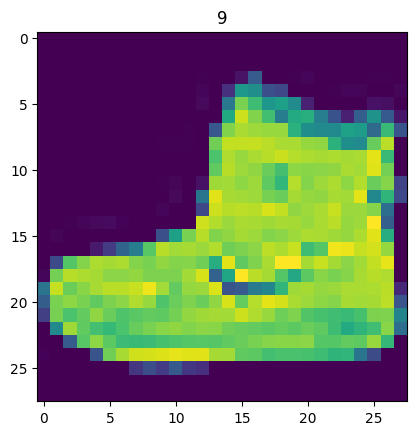

In [ ]:
#Visualizing our data

import matplotlib.pyplot as plt
image , label = train_data[0]
print(f"shape of the image:{image.shape}")
plt.imshow(image.squeeze())
plt.title(label)

Text(0.5, 1.0, 'Ankle boot')

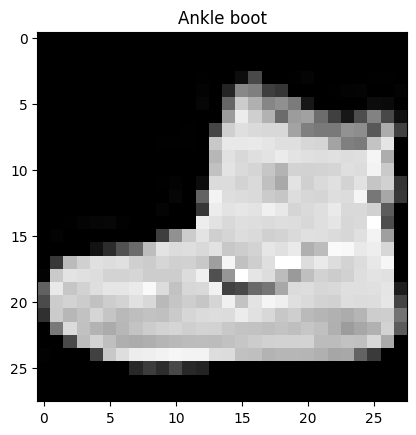

In [ ]:
#change the image to gray scale

plt.imshow(image.squeeze(), cmap='gray')
plt.title(class_names[label])

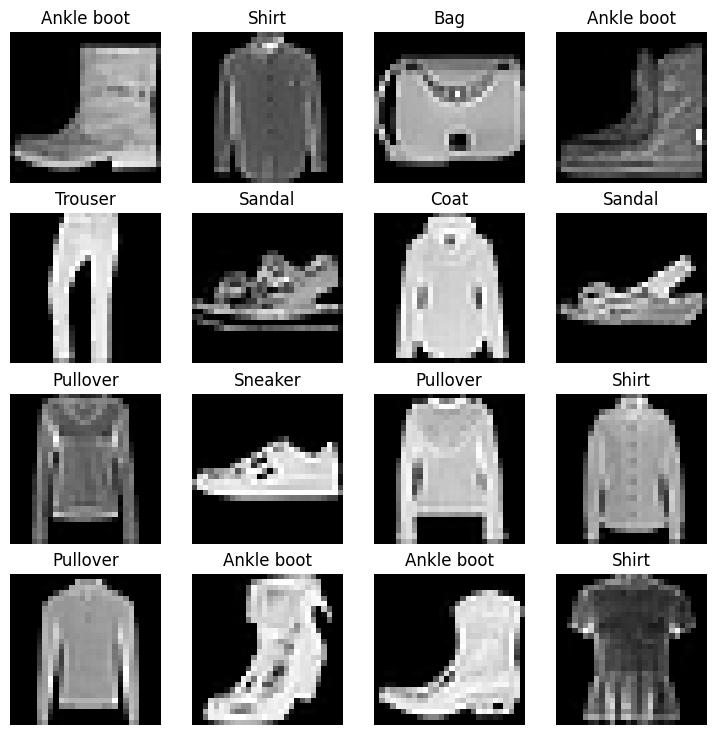

In [ ]:
#plotting more images
torch.manual_seed(42)
plt.figure(figsize=(9,9))
row , column  = 4,4
for i in range(1, row*column +1):
  random_index = torch.randint(0, len(train_data), size=[1]).item()  # .item() changes tensor object into python integer
  image, label = train_data[random_index]
  plt.subplot(row , column , i)
  plt.imshow(image.squeeze(), cmap='gray')
  plt.title(class_names[label])
  plt.axis(False)  # this line hides the axis labels in each subplot

In [ ]:
from torch.utils.data import DataLoader

#setup the batchsize hyper parameter
BACTH_SIZE = 32

#turn datasets into iterable (batches)

train_dataloader = DataLoader( train_data, #dataset to turn into iterable
                              batch_size = BACTH_SIZE ,  #how many samples per batch
                               shuffle = True  #shuffle the data every epoch
                  )

test_dataloader = DataLoader (test_data ,
                              batch_size = BACTH_SIZE ,
                              shuffle = False #dont necessarily has to be shuffled because we are testing the model performance
                )

#lets check out what we have created
print(f"Dataloaders: {train_dataloader , test_dataloader}")
print(f"lenght of train dataloader:{len(train_dataloader)} and batch_size:{BACTH_SIZE}")
print(f"Length of test_dataloader:{len(test_dataloader)} and batch_size: {BACTH_SIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7b911e449bb0>, <torch.utils.data.dataloader.DataLoader object at 0x7b911e9677a0>)
lenght of train dataloader:1875 and batch_size:32
Length of test_dataloader:313 and batch_size: 32


In [ ]:
#check whats inside the train_dataloader

train_features_batch , train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape , train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

image shape: torch.Size([1, 28, 28])
label: 6 label size :torch.Size([])


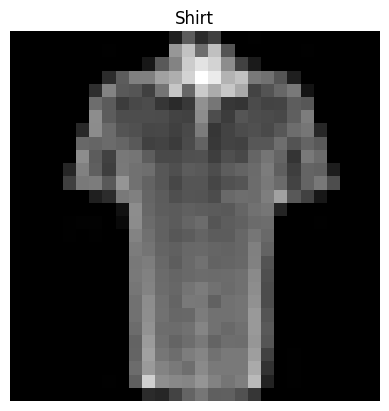

In [ ]:
#show a sample

torch.manual_seed(42)

random_index = torch.randint(0, len(train_features_batch), size=[1]).item()
image, label = train_features_batch[random_index] , train_labels_batch[random_index]
plt.imshow(image.squeeze(), cmap='gray')
plt.title(class_names[label])
plt.axis(False)
print(f"image shape: {image.shape}")
print(f"label: {label} label size :{label.shape}")

Now, lets start by building a baseline model

In [ ]:
#create a flatten layer

flatten_model = nn.Flatten()  # all nn modules can function as a model

#Get a single sample
x = train_features_batch[0]

#flatten the sample (forward pass)
output = flatten_model(x)  #perform forward pass

#print out what happened
print(f"The shape of the sample before flattening: {x.shape}")
print(f"The shape of the sample after flattening :{output.shape}")

#print(x)
#print(output)


The shape of the sample before flattening: torch.Size([1, 28, 28])
The shape of the sample after flattening :torch.Size([1, 784])


In [ ]:
from torch import nn

class FashionMNISTV0(nn.Module):
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
                      nn.Flatten(),  #neural networks like their input in vector form
                      nn.Linear(in_features=input_shape, out_features= hidden_units), # in_features = number of features in data Samples(784 pixels)
                      nn.Linear(in_features= hidden_units, out_features= output_shape)
    )

  def forward(self,x: torch.tensor)-> torch.tensor :
    return self.layer_stack(x)


In [ ]:
torch.manual_seed(42)

#create an instance of the model class we just defined
model_0 = FashionMNISTV0(input_shape=784,  #one for every pixel (28*28)
                         hidden_units=10, #how many units in the hidden layer
                         output_shape=10 ) #one for every class

model_0.to("cpu")  #lets keep model in CPU to begin with

FashionMNISTV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_function.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open ("helper_functions.py", "wb") as f:
    f.write(request.content)

In [ ]:
#import accuracy metric
from helper_functions import accuracy_fn  #we could also use torchmetrics.Accuracy(task= multiclass, num_classes= len(class_names)).to(device)


#setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()  #this is also called criterion or cost function in some places
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)



In [ ]:
from timeit import default_timer as timer

def print_train_time(start: float, end:float, device: torch.device = None):
  """ prints time difference between start  and end time:

  Args:
  start (float): start time of computation(preferred format in timeit )
  end(float): end time of the computation
  device([type],optional): Device that compute is running on( by default it takes none value i.e CPU )

  Returns:
  float: time between start and end of compute in seconds ( higher means longer)
  """
  total_time = end - start
  print(f"The total time taken in {device}: {total_time:.3f} seconds")
  return total_time

In [ ]:
#lets start creating a training loop and testing loop

#lets create the progress bar
from tqdm.auto import tqdm

#lets start manual see and start timer
torch.manual_seed(42)
train_time_start_on_cpu = timer()

#create the epoch for training, lets keep 3 for now for faster compute
epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}\nnnn")

  #training
  train_loss = 0
  for batch, (x,y) in enumerate(train_dataloader):
    model_0.train()

    #forward pass
    y_pred = model_0(x)

    #calculate  (per batch)
    loss = loss_fn(y_pred, y)
    train_loss += loss

    #optimize zero grad
    optimizer.zero_grad()
    #loss backward
    loss.backward()

    #optimizer step
    optimizer.step()

    #print out how many samples have been seen
    if batch % 400 == 0:
      print(f"looked at {batch*len(x)}/{len(train_dataloader.dataset)}")

  train_loss /= len(train_dataloader)  #dividing by number of batches gives average loss per bacth in total train dataset
  #testing , setup the test loss and accuracy variables
  test_loss , accuracy = 0,0
  model_0.eval()
  with torch.inference_mode():
    for x, y in test_dataloader:
      #forward pass
      test_pred = model_0(x)

      #calculate test loss in every batch and sums it to total loss
      test_loss += loss_fn(test_pred, y)

      #calculate the accuracy in every bacth and sums it to total accuracy
      accuracy += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))  #argmax picks the maximum probability of class predicted by model

    #total accumulative test_loss across all batches  can be averaged
    test_loss /= len(test_dataloader)

    #total accuracy accross all the batched can be averaged
    accuracy /= len(test_dataloader)
  #print out whats happening
  print(f"The total train loss is :{train_loss:.5f} , test loss is: {test_loss:.5f} and total accuracy is:{accuracy:.2f}%")


#calculate the total train time
train_time_end_on_cpu = timer()
time_taken_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end = train_time_end_on_cpu,
                                            device= str(next(model_0.parameters()).device)
                                            )


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
nnn
looked at 0/60000
looked at 12800/60000
looked at 25600/60000
looked at 38400/60000
looked at 51200/60000
The total train loss is :0.59039 , test loss is: 0.50954 and total accuracy is:82.04%
Epoch: 1
nnn
looked at 0/60000
looked at 12800/60000
looked at 25600/60000
looked at 38400/60000
looked at 51200/60000
The total train loss is :0.47633 , test loss is: 0.47989 and total accuracy is:83.20%
Epoch: 2
nnn
looked at 0/60000
looked at 12800/60000
looked at 25600/60000
looked at 38400/60000
looked at 51200/60000
The total train loss is :0.45503 , test loss is: 0.47664 and total accuracy is:83.43%
The total time taken in cpu: 26.850 seconds


We create an evaluation function that evaluates the loss and accuracy of model

In [ ]:
#lets create a evaluation function that can peform evaluation by taking
#model, dataloader, loss and accuracy function

torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               dataloader: torch.utils.data.dataloader,
               loss_fn : torch.nn.Module,
               accuracy_fn):

  #test the model
  model.eval()
  loss , accuracy = 0,0
  with torch.inference_mode():
    for x,y in dataloader:

      #forward pass
      test_pred = model(x)

      #calculate the loss
      loss += loss_fn(test_pred, y)

      #calculate the accuracy
      accuracy += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))

    #calculate the average loss and accuracy of  model
    loss /= len(dataloader)
    accuracy /= len(dataloader)

  return {"model_name":model.__class__.__name__,
          "model_loss":loss.item(),
          "model_accuracy": accuracy}

#calculate the model_0 performance in the test dataset
model_0_results = eval_model(model=model_0,
                             dataloader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn)
model_0_results

{'model_name': 'FashionMNISTV0',
 'model_loss': 0.47663894295692444,
 'model_accuracy': 83.42651757188499}

Now we think of using GPU insted of CPU and making better models using non-linearity

In [ ]:
#setup device agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
#lets create a model with non-linear and linear functions layers

class FashionMNISTV1(nn.Module):
  def __init__(self,input_shape:int, hidden_units:int, output_shape:int):
    super().__init__()
    self.layer_stack = nn.Sequential(
                        nn.Flatten(), #flatten the 2 dimention of 28*28 into one single vector of 784 pixel
                        nn.Linear(in_features=input_shape, out_features=hidden_units),
                        nn.ReLU(),
                        nn.Linear(in_features=hidden_units, out_features=output_shape),
                        nn.ReLU()
    )

  def forward(self, x: torch.Tensor)-> torch.tensor:
    return self.layer_stack(x)

In [ ]:
#now time to instantiate the model with same attributes as before

model_1 = FashionMNISTV1(input_shape=784,
                         hidden_units=10,
                         output_shape=len(class_names))

model_1.to(device)  #put the model in cuda if available
next(model_1.parameters()).device   #lets check where the model lives

device(type='cpu')

In [ ]:
from helper_functions import accuracy_fn

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

In [ ]:
#now lets start by defining training loop and testing loop

def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device):
  train_loss , train_accuracy = 0,0
  for batch, (x,y) in enumerate(dataloader):

    #send data to GPU device
    x, y = x.to(device) , y.to(device)
    model.train()

    #forward pass
    y_pred = model(x)

    #loss
    loss = loss_fn(y_pred, y)
    train_loss += loss
    #accuracy
    train_accuracy += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

    #optimize zero grad
    optimizer.zero_grad()

    #loss backward
    loss.backward()

    #optimizer step
    optimizer.step()

  train_loss /= len(dataloader)
  train_accuracy /= len(dataloader)
  print(f"The train loss:{train_loss:.5f} and train accuracy:{train_accuracy:.2f}%")


def test_step(model : torch.nn.Module,
              dataloader : torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer,
              accuracy_fn,
              device: torch.device = None):

  test_loss , test_accuracy = 0,0
  model.eval()

  with torch.inference_mode():
    for x , y in dataloader:

      #send data to GPU device
      x, y = x.to(device) , y.to(device)

      #forward pass
      test_pred = model(x)

      #calculate loss
      test_loss += loss_fn(test_pred, y)

      #calculate accuracy
      test_accuracy += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))

    #calculate the average test loss and test accuracy
    test_loss /= len(dataloader)
    test_accuracy /= len(dataloader)
    print( f"The test_loss:{test_loss:.5f} and test_accuracy:{test_accuracy:.2f}%")

In [ ]:
#lets start training our module

torch.manual_seed(42)

#measur time
from timeit import default_timer as timer
train_time_start_GPU =  timer()

epochs = 3
for epoch in tqdm(range(epochs)):
    print(f"Epoch:{epoch}\n----------")

    train_step(model=model_1,
               dataloader = train_dataloader,
               loss_fn= loss_fn,
               optimizer = optimizer,
               accuracy_fn= accuracy_fn,
               device = device
               )

    test_step(model = model_1,
              dataloader = test_dataloader,
              loss_fn = loss_fn,
              optimizer = optimizer,
              accuracy_fn = accuracy_fn,
              device = device)

train_time_end_GPU = timer()

time_taken_model_1 = print_train_time(start= train_time_start_GPU,
                 end = train_time_end_GPU,
                 device=str(next(model_1.parameters()).device)
                    )

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:0
----------
The train loss:0.98248 and train accuracy:65.06%
The test_loss:0.76060 and test_accuracy:72.80%
Epoch:1
----------
The train loss:0.70374 and train accuracy:74.43%
The test_loss:0.71959 and test_accuracy:73.53%
Epoch:2
----------
The train loss:0.67371 and train accuracy:75.37%
The test_loss:0.69469 and test_accuracy:74.71%
The total time taken in cpu: 25.767 seconds


In [ ]:
#lets evaluate our model using the eval function we defined

torch.manual_seed(42)

model_1_results = eval_model(model=model_1,
                             dataloader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn)
model_1_results

{'model_name': 'FashionMNISTV1',
 'model_loss': 0.6946898102760315,
 'model_accuracy': 74.71046325878594}

In [ ]:
#move values to the device

def eval_model(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device = device):



    """Evaluates a given model on a given dataset.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.
        device (str, optional): Target device to compute on. Defaults to device.

    Returns:
        (dict): Results of model making predictions on data_loader.
        """
    #initialize the test loss and accyracy


    test_loss, accuracy = 0,0

    model.eval()
    with torch.inference_mode():
      for x, y in dataloader:
        x, y = x.to(device), y.to(device)

        test_pred = model(x)

        #loss
        test_loss += loss_fn(test_pred, y)

        #accuracy
        accuracy += accuracy_fn(y_true=y, y_pred = test_pred.argmax(dim=1))

      #calculate the average loss and accuracy across all batches
      test_loss /= len(dataloader)
      accuracy /= len(dataloader)

    return {"model_name": model.__class__.__name__,
            "model_loss":test_loss.item(),
            "model_accuracy": accuracy}

#lets evaluate the model we trained
model_1_results = eval_model(model=model_1,
                             dataloader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn,
                             device = device)
model_1_results

{'model_name': 'FashionMNISTV1',
 'model_loss': 0.6946898102760315,
 'model_accuracy': 74.71046325878594}

In [ ]:
#check baseline results
model_0_results

{'model_name': 'FashionMNISTV0',
 'model_loss': 0.47663894295692444,
 'model_accuracy': 83.42651757188499}

Model 2: Building a Convolutional Neural Network (CNN)

In [ ]:
#lets create a convolutional network

class FashionMNISTV2(nn.Module):
  def __init__(self, input_shape: int,  hidden_units: int, output_shape: int):

    """
    Model architecture copying TinyVGG from:
    https://poloclub.github.io/cnn-explainer/
    """

    super().__init__()
    self.block_1 = nn.Sequential(
    nn.Conv2d(in_channels = input_shape,
                  out_channels = hidden_units,
                   kernel_size = 3, #how big is the square thats going over the image
                   stride = 1, #default
                   padding = 1), #  # options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number
    nn.ReLU(),
    nn.Conv2d( in_channels = hidden_units,
              out_channels = hidden_units,
                kernel_size = 3,
                stride = 1,
                padding = 1),
    nn.ReLU(),
    nn.MaxPool2d(
      kernel_size = 2,
      stride = 2  #default stride value is as same as kernel size
      )
    )
    self.block_2 = nn.Sequential(
        nn.Conv2d(in_channels = hidden_units,
                  out_channels = hidden_units,
                  kernel_size = 3,
                  stride = 1,
                  padding = 1
                  ),
        nn.ReLU(),
        nn.Conv2d(hidden_units,
                  hidden_units,
                  3,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        #where did this in_features come from
        #because each layer of the network compresses and change the shape of out input data
        nn.Linear(in_features=hidden_units*7*7,
                out_features = output_shape)
    )

  def forward(self,x: torch.tensor) -> torch.tensor:
        x = self.block_1(x)
        # print(x.shape)
        x = self.block_2(x)
        #print(x.shape)
        x = self.classifier(x)
        #print(x.shape)
        return x

torch.manual_seed(42)

model_2 = FashionMNISTV2(input_shape=1,
                         hidden_units = 10,
                         output_shape = len(class_names)).to(device) #putting the model into respective device

model_2

FashionMNISTV2(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

You've correctly identified a crucial distinction between the `FashionMNISTV0`/`V1` models and `FashionMNISTV2`!

Here's why `input_shape` is `1` for the CNN (`FashionMNISTV2`) and `784` for the previous MLP models (`FashionMNISTV0`, `FashionMNISTV1`):

1.  **Fully Connected (MLP) Models (`FashionMNISTV0`, `FashionMNISTV1`):**
    *   These models expect a **1-dimensional vector** as input. Since images are 2D (or 3D if they have multiple color channels), they first need to be "flattened" into a single long vector.
    *   For a 28x28 pixel grayscale image, flattening it results in `28 * 28 = 784` individual pixel values. Thus, the `in_features` for the first `nn.Linear` layer (which is what `input_shape` fed into) was `784`.
    *   The `nn.Flatten()` layer explicitly performs this operation at the beginning of these models, converting the `[batch_size, 1, 28, 28]` image tensor into `[batch_size, 784]`.

2.  **Convolutional Neural Network (CNN) Model (`FashionMNISTV2`):**
    *   CNNs are designed to work directly with the **spatial structure** of images. They process the image as a 2D (or 3D) grid, preserving its height and width dimensions through convolutional and pooling layers.
    *   The first layer in a CNN, an `nn.Conv2d` layer, expects input in the format `[batch_size, channels, height, width]`.
    *   Therefore, the `input_shape` parameter for the `FashionMNISTV2` class (which is used as `in_channels` for the first `nn.Conv2d` layer) refers to the **number of color channels** in the input image.
    *   Since FashionMNIST images are grayscale, they have only **1 color channel**. If you were working with RGB images (like from CIFAR-10), you would set `input_shape=3`.

In summary, MLP models flatten the image features into a single vector, so `input_shape` is the total number of pixels. CNN models process the image's channel and spatial dimensions separately, so `input_shape` refers to the number of color channels.

Let's break down how the input shape changes through your `FashionMNISTV2` model to understand why `in_features` becomes `hidden_units * 7 * 7`:

1.  **Initial Input Shape:** Your images are `1` (channel) x `28` (height) x `28` (width).

2.  **`block_1` processing:**
    *   `nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=1)`: With `kernel_size=3`, `stride=1`, and `padding=1`, the spatial dimensions (height and width) remain the same. So, after this layer, the shape is `hidden_units` x `28` x `28`.
    *   `nn.Conv2d(...)` (second conv in block 1): Again, with `kernel_size=3`, `stride=1`, `padding=1`, the spatial dimensions remain `28` x `28`. The output shape is still `hidden_units` x `28` x `28`.
    *   `nn.MaxPool2d(2)`: A max-pooling layer with a kernel size of 2 (which implies a stride of 2 by default) halves the spatial dimensions. So, `28 / 2 = 14`. After this layer, the shape becomes `hidden_units` x `14` x `14`.

3.  **`block_2` processing:**
    *   `nn.Conv2d(...)` (first conv in block 2): Similar to block 1, `kernel_size=3`, `stride=1`, `padding=1` keeps the `14` x `14` spatial dimensions. The shape is `hidden_units` x `14` x `14`.
    *   `nn.Conv2d(...)` (second conv in block 2): Spatial dimensions remain `14` x `14`. The shape is `hidden_units` x `14` x `14`.
    *   `nn.MaxPool2d(2)`: This again halves the spatial dimensions. So, `14 / 2 = 7`. After this layer, the shape becomes `hidden_units` x `7` x `7`.

4.  **`nn.Flatten()`:** This layer takes the output from `block_2` (which is `hidden_units` x `7` x `7`) and flattens it into a single vector. The length of this vector will be `hidden_units * 7 * 7`.

Therefore, the `nn.Linear` layer that follows `nn.Flatten()` needs to have `in_features` equal to the size of this flattened vector, which is `hidden_units * 7 * 7`.

To test the layers out, let's create some toy data just like the data used on CNN Explainer.

In [ ]:
torch.manual_seed(42)

#lets create simple bacth of random number with same size as image batch
images = torch.randn(size=(32,3,64,64)) #[batch , color channel, height, width]
test_image = images[0]  #get a simgle image for the testing
print(f"The image batch shape:{images.shape}")
print(f"single image shape:{test_image.shape}")
print(f"Single imahe pixel values: \n {test_image}")


The image batch shape:torch.Size([32, 3, 64, 64])
single image shape:torch.Size([3, 64, 64])
Single imahe pixel values: 
 tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.856

In [ ]:
torch.manual_seed(42)

#create convolutional layer as same dimension as TinyVGG
#(try changing) any of the parameters and see what happens

conv_layer = nn.Conv2d(in_channels=3,
                    out_channels=10,
                    kernel_size=3,
                    stride = 1,
                    padding=1) #also try using "valid" or "same" here

#pass the data through convolutional layer

conv_layer(test_image)



tensor([[[ 1.3047,  1.4238,  0.9435,  ...,  0.3078,  0.4244, -0.3909],
         [ 0.6132,  1.5396,  0.0516,  ...,  0.8711,  0.4256, -0.3416],
         [ 1.0524,  0.3662,  1.0114,  ...,  0.2809, -0.2741,  0.3787],
         ...,
         [ 0.0377,  0.2981, -0.2432,  ..., -0.7283, -0.5767, -0.0783],
         [-0.2693, -0.0386, -0.0781,  ...,  0.4228, -0.1802, -0.5140],
         [ 0.5006, -0.5684,  0.1166,  ...,  0.5425, -0.3335,  0.7756]],

        [[-0.1153,  0.5129, -0.7227,  ..., -0.6758,  0.4840, -0.8125],
         [ 0.2266, -0.2840, -0.0319,  ...,  1.5599, -1.2449, -0.4410],
         [-0.6666,  0.2753, -0.1262,  ...,  0.1999, -0.8856, -0.4292],
         ...,
         [-0.0647, -0.1984, -0.6386,  ..., -0.0585, -0.7833, -0.0764],
         [ 0.2940, -0.6306, -0.2052,  ...,  0.2456, -0.7134,  0.7373],
         [-0.1683, -0.8397,  0.2643,  ...,  0.2593, -0.5630,  0.1587]],

        [[ 0.4864, -0.7476, -0.6414,  ...,  0.5477, -1.2156,  0.2989],
         [-0.5791,  0.4414,  0.5100,  ...,  0

In [ ]:
#add extra dimension to the test image

test_image.unsqueeze(dim=0).shape

torch.Size([1, 3, 64, 64])

In [ ]:
#pass the test image through extra layer in the conv layer

conv_layer(test_image.unsqueeze(dim=0)).shape

torch.Size([1, 10, 64, 64])

In [ ]:
#What if we changed the values of conv_layer?

torch.manual_seed(42)

conv_layer_2 = nn.Conv2d(in_channels=3,
                         out_channels=10,
                         kernel_size=(5,5), #the kernel is a square that takes tuple as well
                         stride = 2,
                         padding = 0)
#pass single image through the new conv layer which calls nn.Conv2d and performs forward funtion
conv_layer_2(test_image.unsqueeze(dim=0)).shape



torch.Size([1, 10, 30, 30])

In [ ]:
#check out the conv_layer_2 internal parameters

conv_layer_2.state_dict()

OrderedDict([('weight',
              tensor([[[[ 0.0883,  0.0958, -0.0271,  0.1061, -0.0253],
                        [ 0.0233, -0.0562,  0.0678,  0.1018, -0.0847],
                        [ 0.1004,  0.0216,  0.0853,  0.0156,  0.0557],
                        [-0.0163,  0.0890,  0.0171, -0.0539,  0.0294],
                        [-0.0532, -0.0135, -0.0469,  0.0766, -0.0911]],
              
                       [[-0.0532, -0.0326, -0.0694,  0.0109, -0.1140],
                        [ 0.1043, -0.0981,  0.0891,  0.0192, -0.0375],
                        [ 0.0714,  0.0180,  0.0933,  0.0126, -0.0364],
                        [ 0.0310, -0.0313,  0.0486,  0.1031,  0.0667],
                        [-0.0505,  0.0667,  0.0207,  0.0586, -0.0704]],
              
                       [[-0.1143, -0.0446, -0.0886,  0.0947,  0.0333],
                        [ 0.0478,  0.0365, -0.0020,  0.0904, -0.0820],
                        [ 0.0073, -0.0788,  0.0356, -0.0398,  0.0354],
                     

In [ ]:
#get the shape of weight and bias tensors within the conv_laye_2

print(f" The shape of the weight tensor:{conv_layer_2.weight.shape} -> [out_channels=10, in_channels=3, kernel_size=5, kernel_size=5]")
print(f"The shape of the bias tensor:{conv_layer_2.bias.shape} -> [out_channels=10]")

 The shape of the weight tensor:torch.Size([10, 3, 5, 5]) -> [out_channels=10, in_channels=3, kernel_size=5, kernel_size=5]
The shape of the bias tensor:torch.Size([10]) -> [out_channels=10]


In [ ]:
#print out the original shpe with and without the dimension

print(f"The shape of the test imahge without squeezing the dimension:{test_image.shape}")
print(f"The shape of the image with squeezed dimension:{test_image.unsqueeze(dim=0).shape}")

#create a sample max pool layer
max_pool_layer = nn.MaxPool2d(kernel_size=2)

#pass data through just the conv laye
test_image_through_conv = conv_layer(test_image.unsqueeze(dim=0))
print(f"The shape of the image after passing through the conv layer:{test_image_through_conv.shape}")

#pass the data through the max pool layer
test_image_through_concv_and_max_pool = max_pool_layer(test_image_through_conv)
print(f"The shape of the image after passing through the conv and max pool layer:{test_image_through_concv_and_max_pool.shape}")

The shape of the test imahge without squeezing the dimension:torch.Size([3, 64, 64])
The shape of the image with squeezed dimension:torch.Size([1, 3, 64, 64])
The shape of the image after passing through the conv layer:torch.Size([1, 10, 64, 64])
The shape of the image after passing through the conv and max pool layer:torch.Size([1, 10, 32, 32])


In [ ]:
torch.manual_seed(42)

#create a random tensor of smaller dimension to our image
random_tensor = torch.randn(size=(1,1,2,2))
print(f"The random tensor:{random_tensor} and shape of random tensor:\n{random_tensor.shape}")

#create a max pool layer
max_pool_layer = nn.MaxPool2d(kernel_size=2)  #see what happens when you see the kernel size value

#pass the random tensor through the max pool layer
max_pool_tensor  = max_pool_layer(random_tensor)
print(f"\n Max pool tensor :{max_pool_tensor} -> this is the maximum value from the max random_tensor")
print(f"Max pool tensor shape:{max_pool_tensor.shape}")

The random tensor:tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]]) and shape of random tensor:
torch.Size([1, 1, 2, 2])

 Max pool tensor :tensor([[[[0.3367]]]]) -> this is the maximum value from the max random_tensor
Max pool tensor shape:torch.Size([1, 1, 1, 1])


In [ ]:
#create another random tensor

random_tensro = torch.randn(size=(4,8,9,5,6))

#create an average max pool layer
avg_max_pool_layer = nn.AvgPool2d(kernel_size=2)

#passing that random tensor through this average max pool

avg_max_pool_result = avg_max_pool_layer(random_tensor)

print(f"The random tensor before avg max pool:{random_tensor}")
print(f"avg_max_pool_result : {avg_max_pool_result} and avg max pool tensor shape:{avg_max_pool_result.shape}")

The random tensor before avg max pool:tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])
avg_max_pool_result : tensor([[[[0.2326]]]]) and avg max pool tensor shape:torch.Size([1, 1, 1, 1])


 Setup a loss function and optimizer for model_2

In [ ]:
#setup the loss and optimizer for model 2

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(),
                            lr=0.1)

In [ ]:
#lets train and test out model with the help of function we define before

torch.manual_seed(42)

from timeit import default_timer as timer

train_time_start_model_2 = timer()

#train and test the model

epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch:{epoch}\n----------")

  train_step(model=model_2,
             dataloader = train_dataloader,
             loss_fn = loss_fn,
             optimizer = optimizer,
             accuracy_fn = accuracy_fn,
             device = device)

  test_step(model=model_2,
            dataloader = test_dataloader,
            loss_fn = loss_fn,
            optimizer = optimizer,
            accuracy_fn = accuracy_fn,
            )

  train_time_end_model_2 = timer()

time_taken_model_2 = print_train_time(start=train_time_start_model_2,
                                        end=train_time_end_model_2,
                                        device= device)


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:0
----------
The train loss:0.58653 and train accuracy:78.74%
The test_loss:0.39255 and test_accuracy:86.04%
Epoch:1
----------
The train loss:0.36231 and train accuracy:86.89%
The test_loss:0.35723 and test_accuracy:86.70%
Epoch:2
----------
The train loss:0.32485 and train accuracy:88.22%
The test_loss:0.32124 and test_accuracy:88.02%
The total time taken in cpu: 122.513 seconds


In [ ]:
#get model_2 results

model_2_results = eval_model(model=model_2,
                             dataloader = test_dataloader,
                             loss_fn = loss_fn,
                             accuracy_fn = accuracy_fn)
model_2_results

{'model_name': 'FashionMNISTV2',
 'model_loss': 0.3212365508079529,
 'model_accuracy': 88.01916932907348}

In [ ]:
import pandas as pd

compare_results = pd.DataFrame([model_0_results, model_1_results, model_2_results])
compare_results

,model_name,model_loss,model_accuracy
0,FashionMNISTV0,0.476639,83.426518
1,FashionMNISTV1,0.694690,74.710463
2,FashionMNISTV2,0.321237,88.019169


In [ ]:
#add the training time to the dataframe
compare_results["training_time"] = [time_taken_model_0, time_taken_model_1, time_taken_model_2]
compare_results

,model_name,model_loss,model_accuracy,training_time
0,FashionMNISTV0,0.476639,83.426518,26.849753
1,FashionMNISTV1,0.694690,74.710463,25.766942
2,FashionMNISTV2,0.321237,88.019169,122.512889


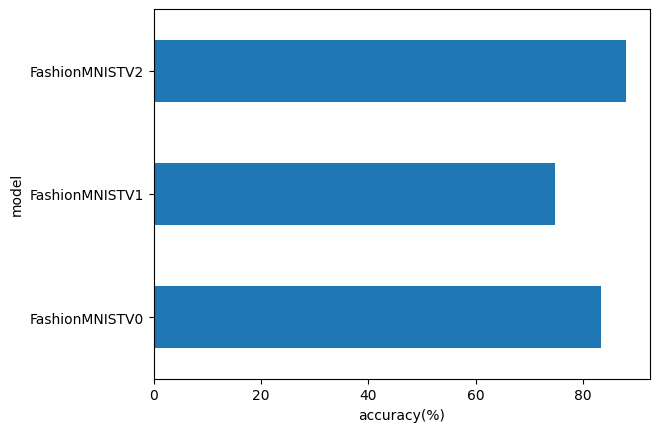

In [ ]:
#lets visualize our model performance

compare_results.set_index("model_name")["model_accuracy"].plot(kind="barh")
plt.xlabel("accuracy(%)")
plt.ylabel("model");


In [ ]:
#lets define a prediction function that evaluates the model predicition

torch.manual_seed(42)

def make_predictions(model: torch.nn.Module,
                     data: list,
                     device: torch.device = device):

  pred_probs = []

  model.eval()
  with torch.inference_mode():
    for sample in data:
      #prepare sample
      sample = torch.unsqueeze(sample, dim=0).to(device)   #adding extra dimension as batch number and put sample into respective device


      #forward function (pass output as raw logit)
      pred_logits = model(sample)

      #perform the softmax function ( logits -> prediction probability )
      pred_prob = torch.softmax(pred_logits.squeeze(), dim=0) #we removed extra batch dimension and specified remaining tensor to be dim=1

      #get the pred_prob off  GPU for other calculations
      pred_probs.append(pred_prob.cpu())


  #stack the probs into one another to turn list into tensor
  return torch.stack(pred_probs)








In [ ]:
import random
torch.manual_seed(42)

test_samples = []
test_labels = []

for sample , label in random.sample(list(test_data), k=9):
  test_samples.append(sample)
  test_labels.append(label)

#view the first ten sample shape and label
print(f"The sample sample image shape:{test_samples[0].shape}\n test sample label:{test_labels[0]} ({class_names[test_labels[0]]})")

The sample sample image shape:torch.Size([1, 28, 28])
 test sample label:8 (Bag)


In [ ]:
#make predictionson test samples with model2

pred_probs = make_predictions(model=model_2,
                              data=test_samples)

#view the first 2 predictions probabilities list
pred_probs[:2]

tensor([[3.9190e-02, 2.4710e-05, 4.4668e-04, 7.4448e-03, 1.2079e-03, 2.4623e-03,
         4.6329e-03, 1.3682e-04, 9.4445e-01, 3.6031e-07],
        [9.4996e-03, 3.0244e-04, 7.1806e-03, 6.3144e-05, 2.7504e-03, 1.2720e-04,
         5.4834e-02, 2.9801e-03, 9.2200e-01, 2.5927e-04]])

In [ ]:
#NOW lets turn the prediction prob into pred labels by taking arg max
pred_classes = pred_probs.argmax(dim=1)

pred_classes

tensor([8, 8, 6, 0, 8, 7, 4, 2, 7])

In [ ]:
#are our predictions in as same foramt as pred labels
test_labels , pred_classes


([8, 8, 6, 6, 8, 7, 6, 4, 7], tensor([8, 8, 6, 0, 8, 7, 4, 2, 7]))

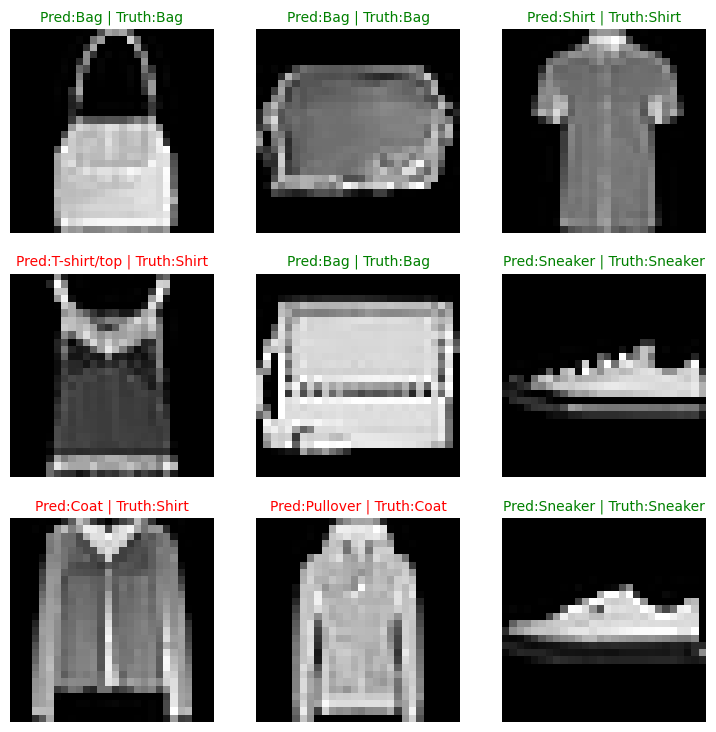

In [ ]:
#lets visualize visualize visualize

#plot predictions
plt.figure(figsize=(9,9))
nrows = 3
ncolumns = 3
for i , sample in enumerate(test_samples):
  #create a subplot
  plt.subplot(nrows, ncolumns, i+1)

  #plot the target image
  plt.imshow(sample.squeeze(), cmap="gray")

  #fins the prediction label (in text form, eg:"sandle")

  pred_label = class_names[pred_classes[i]]

  #get the truth label in the text form

  truth_label = class_names[test_labels[i]]

  #create the title text of the plot
  title_text = f"Pred:{pred_label} | Truth:{truth_label}"

  #check for equality and change title color acccordingly
  if pred_label == truth_label:
    plt.title(title_text, fontsize=10 , c="g") # title green if modle predicts correct
  else:
    plt.title(title_text, fontsize=10 , c="r") #title red if model predicts wrong

  plt.axis(False);

Making a confusion matrix for further prediction evaluation

In [ ]:
#construct confusion matrix

from  tqdm.auto import tqdm

#make predictions using our model_2

y_preds= []
model_2.eval()
with torch.inference_mode():
  for x,y in tqdm(test_dataloader, desc="Making predictions"):
    #send data and traget to target device
    x , y = x.to(device), y.to(device)

    #forward pass
    y_logit = model_2(x)

    #Turn these logits into prediction probabilities and further prediction labels
    y_pred_labels = torch.softmax(y_logit , dim=1).argmax(dim=1)

    #put the prediction in cpu for evaluation
    y_preds.append(y_pred_labels.cpu())

#concetnate the lists of predictions into tensor
y_preds_tensor = torch.cat(y_preds)








Making predictions:   0%|          | 0/313 [00:00<?, ?it/s]

In [ ]:
# See if torchmetrics exists, if not, install it
try:
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")
    assert int(mlxtend.__version__.split(".")[1]) >= 19, "mlxtend verison should be 0.19.0 or higher"
except:
    !pip install -q torchmetrics -U mlxtend # <- Note: If you're using Google Colab, this may require restarting the runtime
    import torchmetrics, mlxtend
    print(f"mlxtend version: {mlxtend.__version__}")

mlxtend version: 0.24.0


In [ ]:
#import mlxtend upgraded version

import mlxtend
print(mlxtend.__version__)
assert int(mlxtend.__version__.split(".")[1]) >= 19

0.24.0


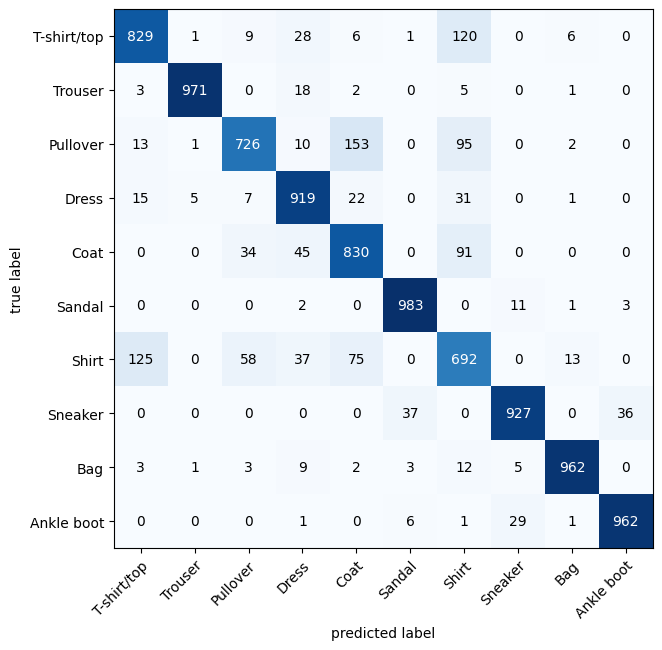

In [ ]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

#setup confusion matrix instance and compare predictions with targets

confmat = ConfusionMatrix(num_classes= len(class_names), task="multiclass")  #cetting up the confusion matric structure
confmat_tensor = confmat(preds= y_preds_tensor, target=test_data.targets)

#plot the confusion matrix

fig, ax = plot_confusion_matrix(conf_mat=confmat_tensor.numpy(), #matplotlib likes working with numpy
                               class_names = class_names,
                               figsize=(10,7) );


In [ ]:
#now lets save the model and try to use model to predict

from pathlib import Path

#create an model directory if one doesnt exist already
MODEL_PATH = Path("model")
MODEL_PATH.mkdir(parents=True,  #create parents directory if needed
                 exist_ok=True) #if models directory already exits, dont cause error


#create   and model save path

MODEL_NAME = "ComputerVsisionModel2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

#save the model sate dict
print(f"saving model to:{MODEL_SAVE_PATH}")
torch.save(obj=model_2.state_dict(), #only saving state_dict onlt saves learning parameters
           f=MODEL_SAVE_PATH)


saving model to:model/ComputerVsisionModel2.pth


In [ ]:
#create an instance of fashionMNIST model (same class as our saved_state_dict())

loaded_model_2 = FashionMNISTV2(input_shape=1,
                              hidden_units=10,
                              output_shape=10)

#load in the saved sate_dict()
loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

#send model to the GPU
loaded_model_2.to(device)


FashionMNISTV2(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [ ]:
#evaluate the loaded model

torch.manual_seed(42)

loaded_model_2_results = eval_model(model=loaded_model_2,
                                   dataloader = test_dataloader,
                                   loss_fn = loss_fn,
                                   accuracy_fn= accuracy_fn)
loaded_model_2_results


{'model_name': 'FashionMNISTV2',
 'model_loss': 0.3212365508079529,
 'model_accuracy': 88.01916932907348}

In [ ]:
model_2_results

{'model_name': 'FashionMNISTV2',
 'model_loss': 0.3212365508079529,
 'model_accuracy': 88.01916932907348}

In [ ]:
#check to see if results of two models are close to eachother (if they are very far away , there maybe an error)

torch.isclose(torch.tensor(model_2_results["model_loss"]),
              torch.tensor(loaded_model_2_results["model_loss"]),
              atol= 1e-08,  #absolute tolerance
              rtol= 0.0001) #zero tolerance

tensor(True)